# Лабораторная работа №7. Построение автокодировщика
**Вариант 1. Скрыпник Михаил Дмитриевич, МИК11.**

Набор disc; единственный фактор: d = 8 → 2. Seed 101–105. Локальный Windows, CPU float32, 4 потока. Все обучения ниже действительно выполняются; числа из демонстрации методички не подставляются. Для повторного запуска откройте блокнот из LR07 с установленными зависимостями.

In [1]:
%%writefile lab07_lib.py
# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):

        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32,
16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model

@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0

    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Writing lab07_lib.py


In [2]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,torch
ROOT=Path.cwd()
assert (ROOT/'src/lab07_experiment.py').exists(), 'Откройте блокнот из LR07'
sys.path.insert(0,str(ROOT/'src'))
import lab07_lib as L
from lab07_experiment import preregister,run_all,summarize
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
pre=preregister()
print(json.dumps(pre,ensure_ascii=False,indent=2))
assert [k for k in pre['A'] if pre['A'][k]!=pre['B'][k]]==['d']

{
  "recorded_at": "2026-10-27T16:39:08+03:00",
  "variant": 1,
  "kind": "disc",
  "factor": "latent_8_to_2",
  "hypothesis": "Сжатие латентного вектора с 8 до 2 чисел снизит PSNR на тесте более чем на 1 дБ. Изменение разрыва train-test останется в пределах 0,1 дБ; изменение времени - в пределах 20%. Основная предполагаемая причина потери качества - недостаточное узкое место для трёх факторов сцены.",
  "A": {
    "arch": "conv",
    "d": 8,
    "loss": "mse",
    "noise": 0.0,
    "eval_noise": 0.0,
    "n_train": 4096,
    "epochs": 20
  },
  "B": {
    "arch": "conv",
    "d": 2,
    "loss": "mse",
    "noise": 0.0,
    "eval_noise": 0.0,
    "n_train": 4096,
    "epochs": 20
  },
  "seeds": [
    101,
    102,
    103,
    104,
    105
  ],
  "data_seed": 7,
  "tolerances": {
    "psnr": 1.0,
    "gap": 0.1,
    "seconds_relative": 0.2
  },
  "tolerance_rationale": {
    "psnr": "Изменение MSE примерно в 1,26 раза считаем практически заметным.",
    "gap": "Сдвиг разрыва менее 0,1

## Основной эксперимент и диагностика
4096 обучающих и 1024 тестовых сцены, seed данных 7. Adam, lr=0.002, batch=128, 20 эпох = 640 обновлений. Один прогрев, затем A/B для seed 101–105. Диагностика d=1,2,3,4,8 по seed 101–103; результаты d=2 и d=8 используются из основной серии.

In [3]:
# Это ячейка фактического обучения, а не загрузка заранее заданных чисел.
result=run_all()
print('Таблица результатов:')
for r in result['summary']:
    print(json.dumps(r,ensure_ascii=False))

2026-10-27T16:39:08+03:00 Гипотеза и допуски записаны ДО обучения: 2026-10-27T16:39:08+03:00


2026-10-27T16:39:08+03:00 Среда 2.11.0+cpu; cpu; средняя картинка PSNR=17.170731


2026-10-27T16:39:08+03:00 Прогрев: полный режим A, seed 0; не входит в статистику


2026-10-27T16:39:32+03:00 Начало A, seed=101, d=8, 20 эпох


2026-10-27T16:39:56+03:00 Готово A, seed=101: PSNR=25.849468; gap=0.040106; время=23.50 с


...

2026-10-27T16:47:00+03:00 Диагностика d=4, seed=102: PSNR=26.336060


2026-10-27T16:47:00+03:00 Диагностика d=4, seed=103, 20 эпох


2026-10-27T16:47:24+03:00 Диагностика d=4, seed=103: PSNR=26.156200


2026-10-27T16:47:24+03:00 Все 19 измеряемых обучений завершены: 10 основных + 9 дополнительных; 6 диагностических точек переиспользуют основную серию.


Таблица результатов:
{"metric": "psnr", "A": 25.75871925354004, "s": 0.8494110208045333, "B": 23.17343635559082, "delta": -2.58528289794922, "ratio": 3.043618265631317, "criterion_2s": true, "threshold": 1.0, "outside_tolerance": true, "classification": "ухудшение"}
{"metric": "gap", "A": 0.04030914306640625, "s": 0.012185881561719165, "B": 0.09293861389160156, "delta": 0.05262947082519531, "ratio": 4.318889081486398, "criterion_2s": true, "threshold": 0.1, "outside_tolerance": false, "classification": "нейтрально"}
{"metric": "params", "A": 101.035, "s": 0.0, "B": 88.741, "delta": -12.293999999999997, "ratio": null, "criterion_2s": true, "threshold": null, "outside_tolerance": null, "classification": "снижение числа параметров"}
{"metric": "seconds", "A": 24.560798059997616, "s": 1.240922932474063, "B": 24.746958719997203, "delta": 0.18616065999958664, "ratio": 0.15001790613090926, "criterion_2s": false, "threshold": 4.912159611999524, "outside_tolerance": false, "classification": "не

## Независимая проверка сохранённых весов
Повторная реконструкция всех 1024 тестовых сцен и 1024 обучающих сцен для каждой из 10 моделей. PSNR усредняется по изображениям.

In [4]:
from datetime import datetime
Xtr,Xte,_,_=L.dataset('disc')
assert hashlib.sha256(Xtr.cpu().numpy().tobytes()+Xte.cpu().numpy().tobytes()).hexdigest()==result['dataset']['sha256']
for r in result['measurements']:
    assert datetime.fromisoformat(pre['recorded_at'])<datetime.fromisoformat(r['started_at'])
    model=L.build('conv',r['d'])
    with np.load(ROOT/r['checkpoint'],allow_pickle=False) as data:
        model.load_state_dict({k:torch.from_numpy(data[k]).to(L.DEVICE) for k in data.files})
    psnr=L.psnr_images(L.reconstruct(model,Xte),Xte)
    gap=L.psnr_images(L.reconstruct(model,Xtr[:1024]),Xtr[:1024])-psnr
    assert abs(psnr-r['psnr'])<1e-6 and abs(gap-r['gap'])<1e-6
    assert L.n_params(model)/1000==r['params']
    print(r['mode'],r['seed'],'PSNR',round(psnr,6),'gap',round(gap,6),'PASS')
assert summarize(result['measurements'],pre)==result['summary']
baseline=L.psnr_images(Xtr.mean(0,keepdim=True).expand_as(Xte),Xte)
assert abs(baseline-result['baseline_psnr'])<1e-6
print('PASS: 10 моделей, все метрики и средняя картинка:',baseline)

A 101 PSNR 25.849468 gap 0.040106 PASS


B 101 PSNR 23.305454 gap 0.09428 PASS


A 102 PSNR 26.226294 gap 0.046743 PASS


B 102 PSNR 23.42346 gap 0.082718 PASS


A 103 PSNR 24.766117 gap 0.019739 PASS


B 103 PSNR 22.657965 gap 0.084379 PASS


A 104 PSNR 25.087158 gap 0.051126 PASS


B 104 PSNR 23.003387 gap 0.077068 PASS


A 105 PSNR 26.864559 gap 0.043831 PASS


B 105 PSNR 23.476915 gap 0.126247 PASS
PASS: 10 моделей, все метрики и средняя картинка: 17.170730590820312


## Лист сравнения
Строки: оригинал, A (d=8), B (d=2). Первые восемь сцен из тестовой выборки; seed 101.

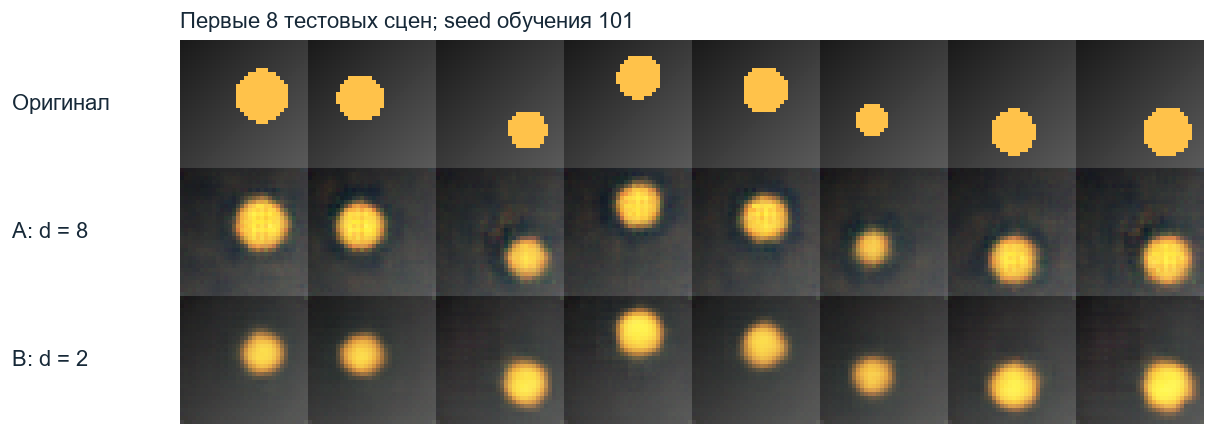

In [5]:
from IPython.display import display
from PIL import Image
display(Image.open(ROOT/'artifacts/comparison_labeled.png'))

## Проверка узкого места и практических допусков
Критерий |Δ|>2s - учебная эвристика, где s - выборочное стандартное отклонение A. Он не является формальным статистическим тестом. Для параметров s=0: отношение не определено, изменение детерминировано.

In [6]:
for r in result['diagnostics']:
    print('d =',r['d'],'PSNR mean =',round(r['mean'],6),'s =',round(r['s'],6),'values =',r['values'])
for r in result['summary']:
    print(r['metric'],r['classification'],'2s =',r['criterion_2s'],'за допуском =',r['outside_tolerance'])
for r in result['summary']:
    if r['threshold'] is not None:
        print('Чувствительность',r['metric'],{k:abs(r['delta'])>k*r['threshold'] for k in [0.5,1,2]})
for mode in ['A','B']:
    p=next(r[mode] for r in result['summary'] if r['metric']=='psnr')
    print(mode,'выигрыш над средней картинкой, дБ:',p-result['baseline_psnr'])

d = 1 PSNR mean = 20.622026 s = 0.11106 values = [20.56284523010254, 20.75014305114746, 20.553089141845703]
d = 2 PSNR mean = 23.12896 s = 0.412139 values = [23.30545425415039, 23.423460006713867, 22.6579647064209]
d = 3 PSNR mean = 25.195988 s = 0.860964 values = [24.76555824279785, 24.63511848449707, 26.187286376953125]
d = 4 PSNR mean = 26.472629 s = 0.402483 values = [26.925626754760742, 26.3360595703125, 26.156200408935547]
d = 8 PSNR mean = 25.61396 s = 0.758042 values = [25.849468231201172, 26.226293563842773, 24.766117095947266]
psnr ухудшение 2s = True за допуском = True
gap нейтрально 2s = True за допуском = False
params снижение числа параметров 2s = True за допуском = None
seconds нейтрально 2s = False за допуском = False
Чувствительность psnr {0.5: True, 1: True, 2: True}
Чувствительность gap {0.5: True, 1: False, 2: False}
Чувствительность seconds {0.5: False, 1: False, 2: False}
A выигрыш над средней картинкой, дБ: 8.587988662719727
B выигрыш над средней картинкой, дБ: 6

## Вывод и ограничения
Численный вывод, визуальная оценка и ответы на 10 контрольных вопросов находятся в PDF-отчёте. Сцена имеет три непрерывных фактора (x, y, радиус); недостаток узкого места проверяется по серии и диагностике. Обобщение на фотографии не проверено. Время относится к CPU и включает создание модели, оптимизатора и обучение, как в функции L.run; генерация данных, оценка, сохранение весов и изображений не входят. Методичка сохранена в assignment/.